---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 17 (DerbyCounty)

- Juan Oloando Simanungkalit (13524032) - juanoloando.s@gmail.com
- Nashiruddin Akram (13524090) - akrambaasir@gmail.com
- Reinsen Silitonga (13524093) - reinsilitonga12@gmail.com
- Arghawisesa Dwinanda Arham (13524100) - arghaku.argha@gmail.com
- Manuel Thimoty Silalahi (13524102) - manuelsilalahi06@gmail.com

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Penyelenggara penginapan ingin memprediksi apakah sebuah pemesanan akan dibatalkan (`is_canceled`) dari data pemesanan seperti lead time, jumlah malam, harga, kanal pemesanan, dan permintaan khusus.

## Aim

Membangun model klasifikasi biner from scratch yang memaksimalkan Macro F1 pada data test Kaggle, dengan pipeline yang reproducible.

## Metric

Macro F1 = rata-rata F1 kelas 0 dan F1 kelas 1. Kedua kelas berbobot sama, jadi model tidak cukup hanya bagus di kelas mayoritas.

## Dataset

`train.csv` berisi 27.373 baris dengan 17 fitur dan label, `test.csv` berisi 6.844 baris tanpa label. Ada missing value, duplikat, dan nilai tidak valid.

## Approach

Preprocessing eksperimen DT: dedupe, `num_adults = 0` jadi missing, fitur turunan (opsional), dan penggabungan kategori langka. Missing dan kategori dibiarkan karena Decision Tree from scratch bisa menanganinya langsung, dan tidak ada scaling.

### Perubahan dari `dtl_entropy_mingain`

- Criterion gain ratio (C4.5): information gain dibagi split information.
- Terpilih min gain 2e-4 dan `min_samples_leaf` 5. Submission ini public tertinggi DTL (0.84679).

**Alasan.** Information gain cenderung memilih split yang memecah data jadi bagian yang sangat tidak seimbang. Gain ratio menormalkan gain dengan split information, sehingga split lebih seimbang dan pohon lebih stabil (std per fold paling kecil).

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import hashlib
import heapq
import math
import os
import pickle
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.tree import DecisionTreeClassifier

# semua path relatif terhadap root repo; naik folder sampai ketemu data/train.csv
while not Path('data/train.csv').exists() and Path.cwd() != Path.cwd().parent:
    os.chdir('..')
print('working directory:', Path.cwd())

working directory: /home/reinsensilitonga/Documents/kaggle_competitions/IF3170_G17_DerbyCounty


## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED        = 42
    ID_COLUMN   = 'id'
    TARGET      = 'is_canceled'
    N_FOLDS     = 5

    # preprocessing eksperimen DT
    FEATURE_ENGINEERING = True
    RARE_MIN_COUNT      = 20     # kategori dengan jumlah < 20 di data fit digabung jadi 'Other'

    # Decision Tree versi ini dan versi sebelumnya (pembanding)
    DT_PARAMS   = dict(criterion='gain_ratio', max_depth=30, min_samples_leaf=5, min_impurity_decrease=2e-4)
    PREV_PARAMS = dict(criterion='entropy', max_depth=30, min_samples_leaf=3, min_impurity_decrease=4.5e-4)
    PREV_FEATURE_ENGINEERING = True

    # grid search pre-pruning (sama dengan notebook dt_gain_ratio)
    GRID_CRITERION = 'gain_ratio'
    MIN_GAINS      = [1e-4, 2e-4, 2.5e-4, 3e-4, 3.5e-4, 4e-4, 5e-4]
    LEAVES         = [3, 5, 10, 20]

    EXP_NAME   = 'dtl_gain_ratio'
    MODEL_PATH = f'output/models/{EXP_NAME}.pkl'
    SUB_PATH   = f'output/submissions/submission_{EXP_NAME}.csv'

CFG = Settings()

Penjelasan isi `Settings`:

| Nama | Arti |
|---|---|
| `SEED`, `N_FOLDS` | 5-fold cross validation dengan seed 42, sama dengan eksperimen `dt_gain_ratio` |
| `FEATURE_ENGINEERING` | pakai 7 fitur turunan atau tidak |
| `RARE_MIN_COUNT` | batas jumlah kategori langka |
| `DT_PARAMS`, `PREV_PARAMS` | hyperparameter versi ini dan versi sebelumnya |
| `GRID_CRITERION`, `MIN_GAINS`, `LEAVES` | grid search pre-pruning di bagian Improvements |

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv('data/train.csv', dtype={CFG.ID_COLUMN: str})
test_df  = pd.read_csv('data/test.csv', dtype={CFG.ID_COLUMN: str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [7]:
types(train_df)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


In [8]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


Arti tiap kolom:

| Kolom | Arti |
|---|---|
| `num_adults`, `num_children` | jumlah tamu dewasa dan anak |
| `weekend_nights`, `weekday_nights` | jumlah malam akhir pekan dan hari kerja |
| `meal_package` | paket makan (Room Only, Breakfast, Half Board, Full Board) |
| `needs_parking` | butuh tempat parkir (0/1) |
| `room_category` | tipe kamar (Type A sampai G) |
| `days_before_arrival` | lead time, jarak hari antara pemesanan dan kedatangan |
| `arrival_year`, `arrival_month`, `arrival_day` | tanggal kedatangan |
| `booking_channel` | kanal pemesanan (Online Travel Agent, Offline Agent, Corporate, Complimentary, Airline) |
| `is_returning_guest` | tamu yang pernah menginap (0/1) |
| `prior_cancellations`, `prior_completed_bookings` | riwayat pembatalan dan pemesanan selesai |
| `nightly_rate_idr` | harga per malam dalam rupiah |
| `special_requests` | jumlah permintaan khusus |
| `is_canceled` | target, 1 kalau pemesanan dibatalkan |

#### Insights

- Data berisi 27.373 baris, 13 kolom numerik dan 3 kolom kategorikal (`meal_package`, `room_category`, `booking_channel`).
- Lead time sangat menceng ke kanan: median 58 hari, tetapi maksimum 448 hari.
- Harga per malam bermedian sekitar Rp1,64 juta dengan maksimum Rp9,17 juta, dan ada 413 baris berharga 0.
- Kedatangan hanya di tahun 2023 (4.924 baris) dan 2024 (22.449 baris).
- Rentang nilai antarkolom sangat berbeda (harga jutaan, jumlah malam satuan), jadi model berbasis jarak wajib memakai scaling.

## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
def target_rate(df, columns, bins=None):
    figure, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        values = pd.qcut(df[column], bins[column], duplicates='drop') if bins and column in bins else df[column]
        df.groupby(values, observed=True)[CFG.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {CFG.TARGET}')
    plt.tight_layout()
    plt.show()

is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


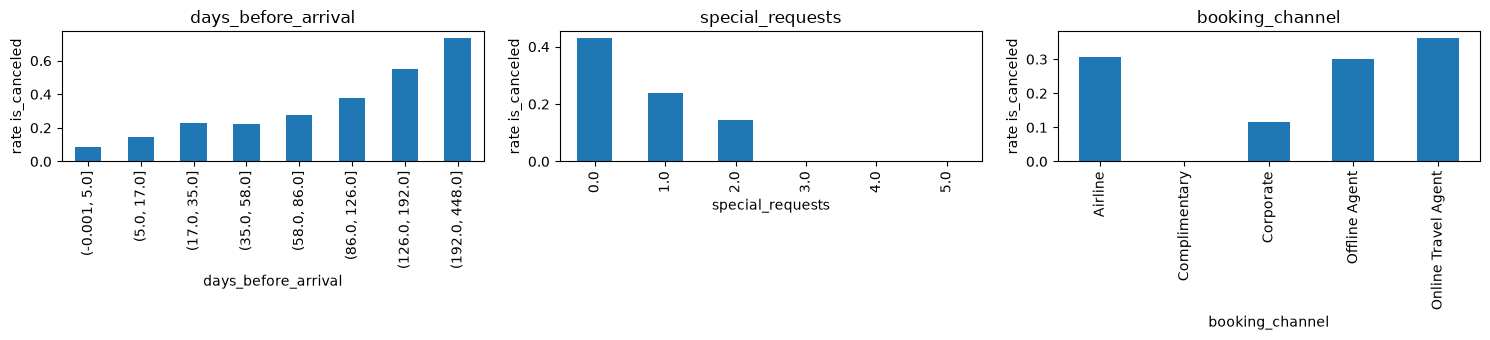

In [10]:
print(train_df[CFG.TARGET].value_counts(normalize=True).round(3))
target_rate(train_df, ['days_before_arrival', 'special_requests', 'booking_channel'], bins={'days_before_arrival': 8})

#### Insights

- Kelas tidak seimbang ringan, sekitar 33% batal. Macro F1 memberi bobot sama ke dua kelas, jadi threshold perlu ditentukan, bukan selalu 0.5.
- Lead time (`days_before_arrival`) dan `special_requests` paling kuat memisahkan kelas: booking jauh hari makin sering batal, tamu dengan permintaan khusus jarang batal. Dua fitur ini nanti diberi bobot 2 di jarak KNN.

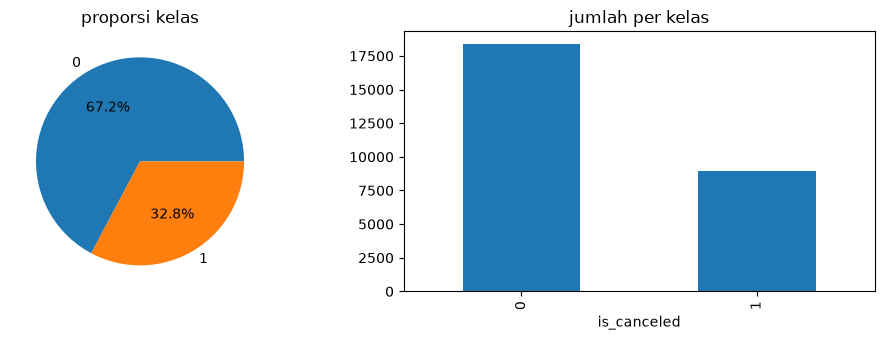

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df[CFG.TARGET].value_counts().plot.pie(ax=axes[0], autopct='%.1f%%', ylabel='', title='proporsi kelas')
train_df[CFG.TARGET].value_counts().plot.bar(ax=axes[1], title='jumlah per kelas')
plt.tight_layout()
plt.show()

Distribusi fitur numerik dipisah per kelas. `density=True` supaya dua kelas yang jumlahnya beda tetap bisa dibandingkan.

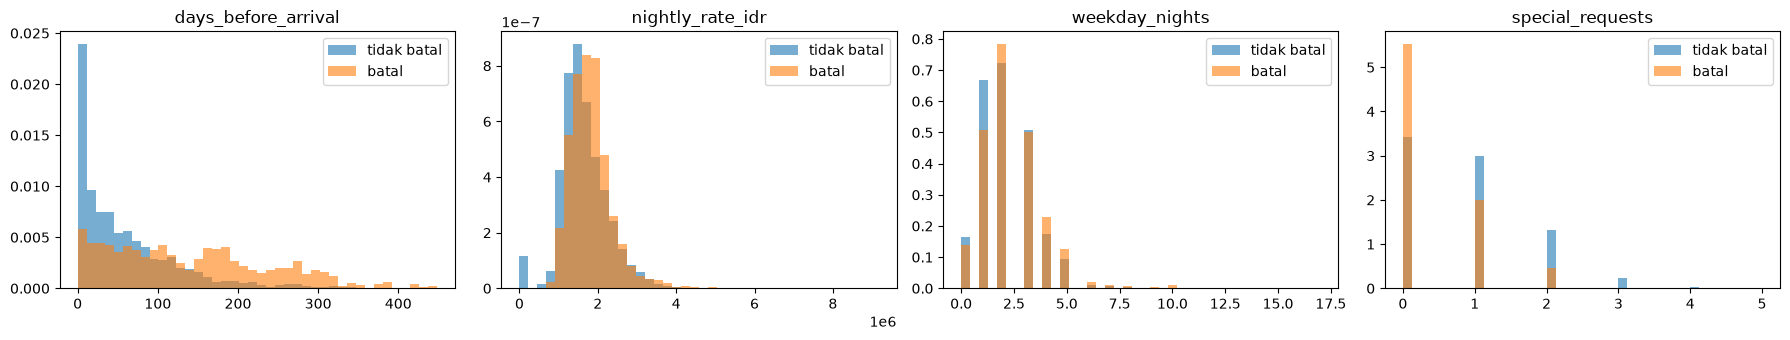

In [12]:
def histogram_by_target(df, columns, bins=40):
    figure, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        edges = np.histogram_bin_edges(df[column].dropna(), bins=bins)
        for label, name in [(0, 'tidak batal'), (1, 'batal')]:
            axis.hist(df.loc[df[CFG.TARGET] == label, column].dropna(), bins=edges, alpha=0.6, density=True, label=name)
        axis.set_title(column)
        axis.legend()
    plt.tight_layout()
    plt.show()

histogram_by_target(train_df, ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'special_requests'])

#### Insights

- Distribusi lead time kelas batal jauh lebih ke kanan. Rasio batal naik dari 8,8% (lead 0 sampai 5 hari) menjadi 73,8% (lead di atas 192 hari).
- Rasio batal naik seiring harga, dari 20,6% di kuintil termurah ke 44,5% di kuintil keempat, lalu turun sedikit di kuintil termahal (36,1%).
- Menginap lebih dari 10 malam punya rasio batal 68,7%, jauh di atas rata-rata.
- Tamu tanpa permintaan khusus batal 43,2%, dengan 1 permintaan 23,8%, dan dengan 3 atau lebih hampir tidak pernah batal.

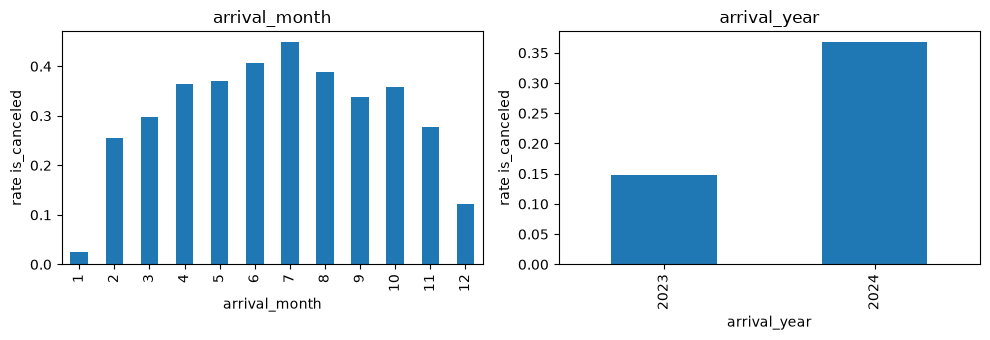

In [13]:
target_rate(train_df, ['arrival_month', 'arrival_year'])

#### Insights

- Ada pola musiman kuat: rasio batal terendah di Januari (2,6%) dan Desember (12,1%), tertinggi di Juli (44,8%).
- Korelasi linear `arrival_month` dengan target hampir 0 (-0,016) karena polanya naik lalu turun. Pola melingkar ini ditangkap oleh `month_cos`, yang membuat Desember dan Januari berdekatan.
- Tahun 2023 hanya 14,7% batal, sedangkan 2024 36,7%. `arrival_year` tidak dipakai langsung karena hanya 2 nilai dan sebagian besar efeknya sudah tertangkap lewat `booking_index`.

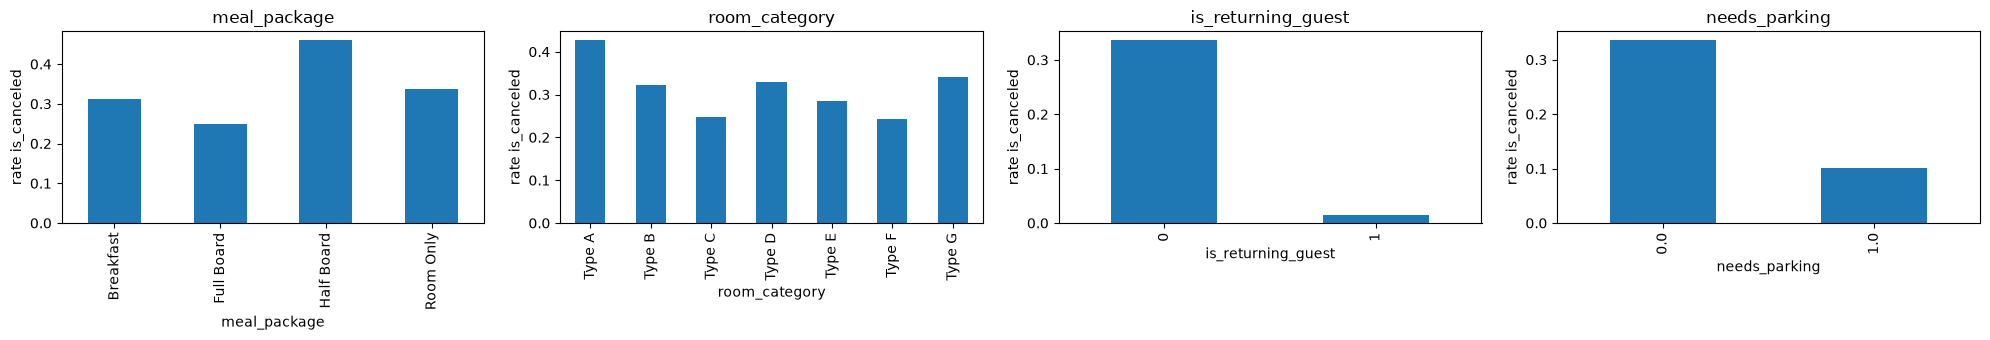

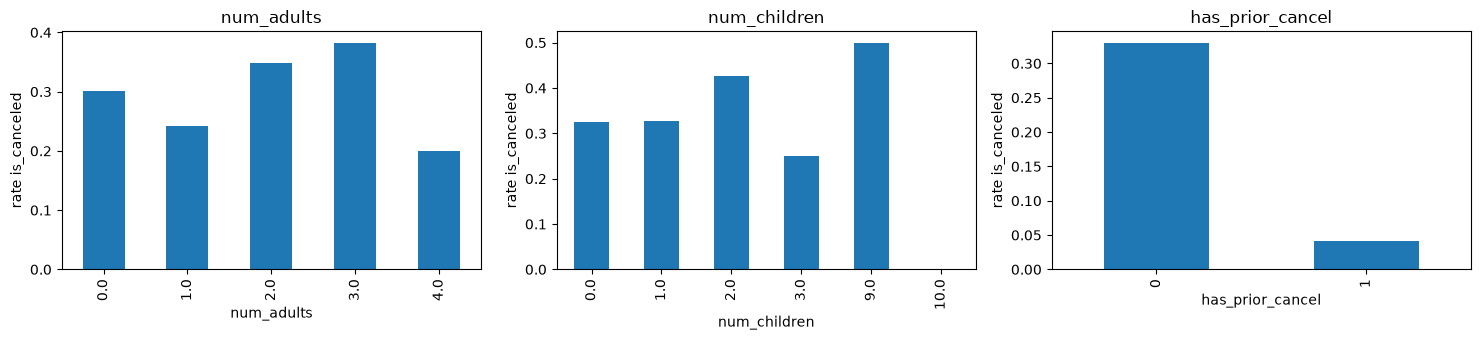

In [14]:
target_rate(train_df, ['meal_package', 'room_category', 'is_returning_guest', 'needs_parking'])
target_rate(train_df.assign(has_prior_cancel=(train_df['prior_cancellations'] > 0).astype(int)),
            ['num_adults', 'num_children', 'has_prior_cancel'])

#### Insights

- Kanal pemesanan sangat berpengaruh: Complimentary 0%, Corporate 11,5%, Offline Agent 30,2%, Online Travel Agent 36,4%.
- Tamu yang pernah menginap hampir tidak pernah batal (1,5% dibanding 33,6%). Tamu yang butuh parkir juga jarang batal (10,1% dibanding 33,5%).
- Paket Half Board paling sering batal (45,9%), sedangkan Full Board hanya 4 baris sehingga tidak bisa disimpulkan.
- Tamu dengan riwayat pembatalan justru jarang batal lagi, tetapi jumlahnya sangat sedikit (sekitar 1%).
- Beberapa kategori sangat jarang (Full Board 4 baris, Type E 7 baris, num_children 9 dan 10). Untuk KNN ini tidak masalah karena kategori jarang hanya menambah jarak.

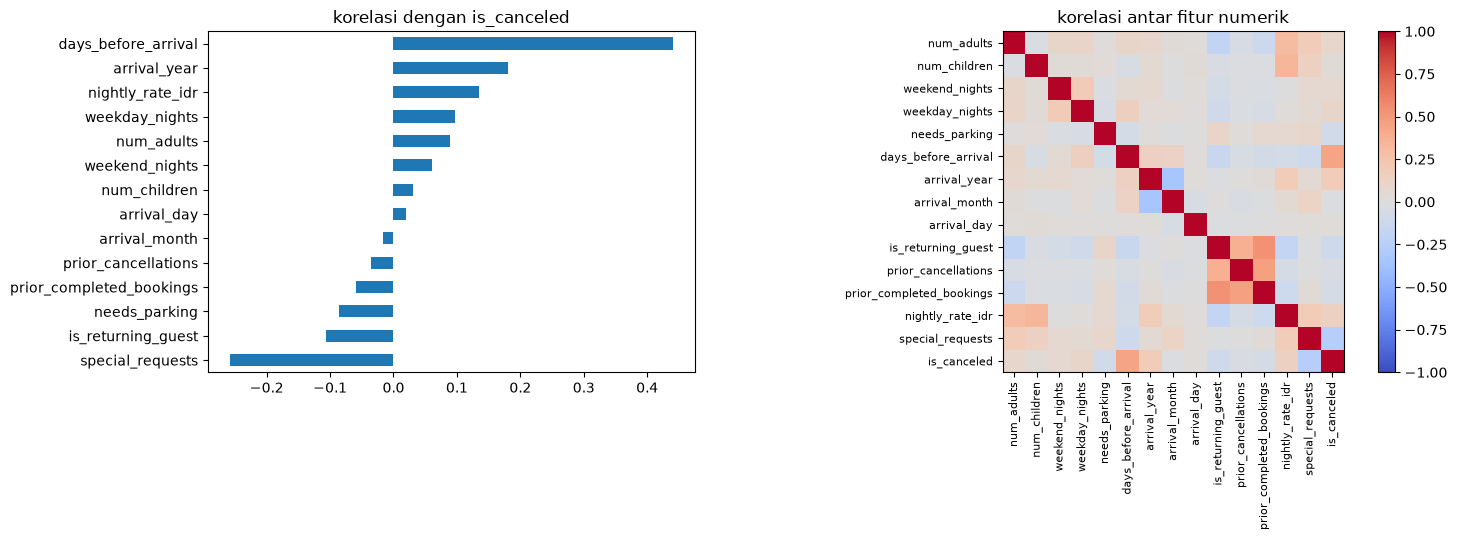

In [15]:
corr = train_df.select_dtypes('number').corr()
figure, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
corr[CFG.TARGET].drop(CFG.TARGET).sort_values().plot.barh(ax=axes[0], title='korelasi dengan is_canceled')
image = axes[1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(corr)), corr.columns, fontsize=8)
axes[1].set_title('korelasi antar fitur numerik')
figure.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

#### Insights

- Korelasi terkuat dengan target: lead time (0,44), special_requests (-0,26), arrival_year (0,18), nightly_rate_idr (0,13), is_returning_guest (-0,11).
- Korelasi antarfitur rendah. Pasangan tertinggi hanya is_returning_guest dengan prior_completed_bookings (0,53), jadi tidak ada fitur yang benar-benar duplikat.
- Korelasi hanya menangkap hubungan linear. Bulan kedatangan berkorelasi hampir 0 tetapi polanya kuat (grafik musiman di atas), jadi seleksi fitur tidak boleh hanya berdasarkan korelasi.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [16]:
def missing(train, test):
    features = test.columns.drop(CFG.ID_COLUMN)
    table = pd.DataFrame({'train': train[features].isna().mean() * 100,
                          'test': test[features].isna().mean() * 100}).round(2)
    return table[table.sum(axis=1) > 0]

def duplicates(df):
    features = df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
    labels = df.groupby(list(features), dropna=False)[CFG.TARGET].nunique()
    return pd.Series({'baris duplikat': df.duplicated(subset=list(features) + [CFG.TARGET]).sum(),
                      'fitur sama, label beda': (labels > 1).sum()})

In [17]:
missing(train_df, test_df)

,train,test
num_adults,2.96,2.63
num_children,11.09,10.91
meal_package,6.43,6.46
needs_parking,3.95,3.61
room_category,3.66,3.54
days_before_arrival,4.10,4.24
nightly_rate_idr,7.45,7.89
special_requests,9.13,8.66


In [18]:
print(duplicates(train_df))
print('num_adults = 0:', (train_df['num_adults'] == 0).sum())

baris duplikat            64
fitur sama, label beda     2
dtype: int64
num_adults = 0: 106


#### Insights

- Missing ada di beberapa kolom (sekitar 2 sampai 11%) dengan proporsi mirip di train dan test, jadi imputasinya harus sama untuk keduanya.
- Ada baris duplikat persis. Kalau dibiarkan, baris yang sama bisa masuk data latih dan validasi sekaligus sehingga skor validasi terlalu optimis.
- Booking tanpa orang dewasa (`num_adults = 0`) tidak masuk akal, jadi dianggap nilai tidak valid.

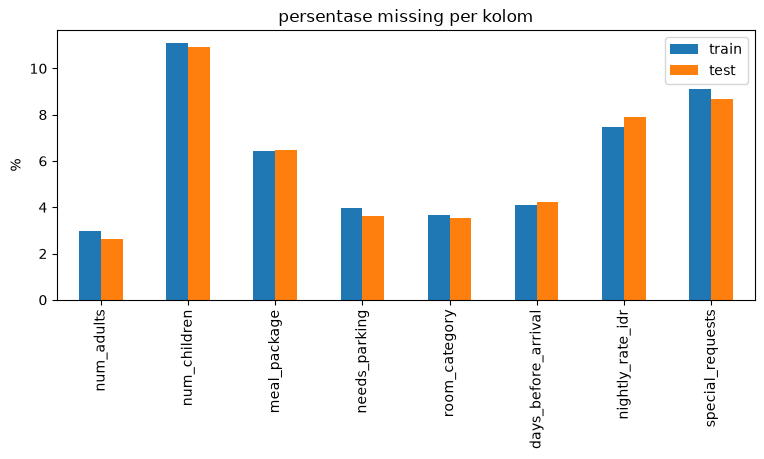

In [19]:
missing(train_df, test_df).plot.bar(figsize=(9, 3.5), title='persentase missing per kolom')
plt.ylabel('%')
plt.show()

Apakah baris yang missing punya rasio batal berbeda? Kalau berbeda, missing itu sendiri membawa informasi.

In [20]:
missing_cols = train_df.columns[train_df.isna().any()]
pd.DataFrame({'rasio batal jika missing': [train_df.loc[train_df[c].isna(), CFG.TARGET].mean() for c in missing_cols],
              'rasio batal jika terisi': [train_df.loc[train_df[c].notna(), CFG.TARGET].mean() for c in missing_cols]},
             index=missing_cols).round(3)

,rasio batal jika missing,rasio batal jika terisi
num_adults,0.335,0.327
num_children,0.328,0.328
meal_package,0.319,0.328
needs_parking,0.312,0.328
room_category,0.348,0.327
days_before_arrival,0.312,0.328
nightly_rate_idr,0.313,0.329
special_requests,0.408,0.320


Pengecekan nilai yang tidak masuk akal.

In [21]:
nights = train_df['weekend_nights'] + train_df['weekday_nights']
pd.Series({'num_adults = 0': (train_df['num_adults'] == 0).sum(),
           'total malam = 0': (nights == 0).sum(),
           'num_children >= 9': (train_df['num_children'] >= 9).sum(),
           'harga 0 bukan Complimentary': ((train_df['nightly_rate_idr'] == 0) & (train_df['booking_channel'] != 'Complimentary')).sum()},
          name='jumlah baris')

num_adults = 0                 106
total malam = 0                 64
num_children >= 9                3
harga 0 bukan Complimentary    146
Name: jumlah baris, dtype: int64

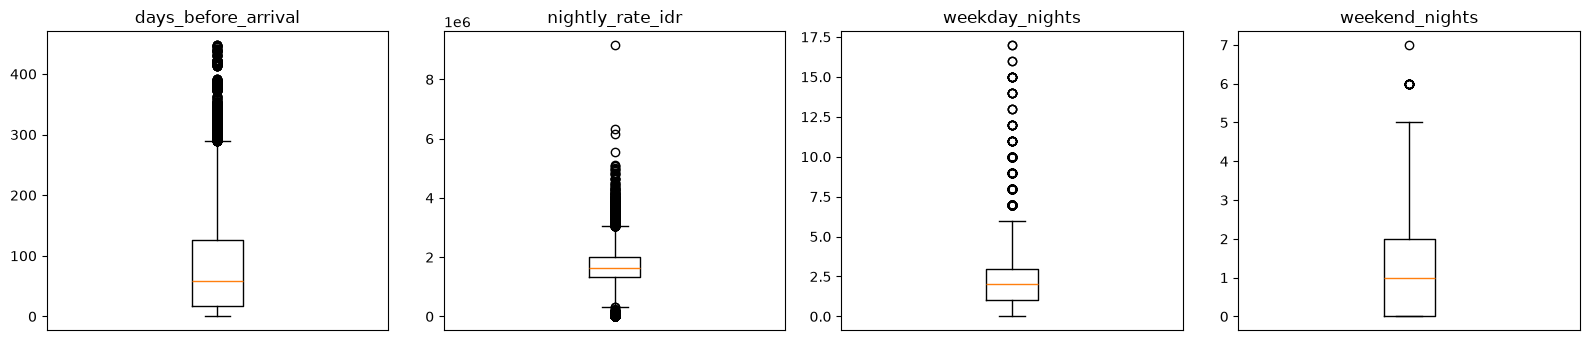

In [22]:
outlier_cols = ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights']
figure, axes = plt.subplots(1, len(outlier_cols), figsize=(4 * len(outlier_cols), 3.5))
for axis, column in zip(axes, outlier_cols):
    axis.boxplot(train_df[column].dropna())
    axis.set_title(column)
    axis.set_xticks([])
plt.tight_layout()
plt.show()

#### Insights

- Missing tersebar acak di 8 kolom: rasio batal baris missing dan terisi hampir sama (selisih di bawah 2 poin persen), kecuali `special_requests` (40,8% jika missing, 32,0% jika terisi). Indikator missing untuk special_requests sudah dicoba di eksperimen, tetapi tidak menaikkan OOF.
- Nilai tidak masuk akal: 106 baris tanpa orang dewasa, 64 baris dengan total malam 0, 3 baris dengan 9 atau 10 anak, dan 146 baris berharga 0 di luar kanal Complimentary. Hanya `num_adults = 0` yang diubah jadi missing, karena mengubah tiga kasus lainnya tidak menaikkan OOF.
- Boxplot menunjukkan ekor panjang di lead time (maksimum 448, persentil 99,5% = 382) dan harga (maksimum Rp9,17 juta, persentil 99,5% = Rp3,73 juta). Nilai ini ditangani dengan clipping di Data Preparation.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [23]:
# fungsi validasi dari eksperimen DT
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')

# threshold dengan Macro F1 tertinggi
def best_threshold(y_true, proba):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = np.array([macro_f1(y_true, (proba >= t).astype(int)) for t in grid])
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])

# stratified k-fold manual: index tiap kelas diacak lalu dibagi bergiliran ke k fold
def stratified_kfold(y, n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

In [24]:
# dedupe tidak mempelajari statistik apa pun, jadi dilakukan sebelum split
features = train_df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
train_clean = train_df.drop_duplicates(subset=list(features) + [CFG.TARGET]).reset_index(drop=True)
y_clean = train_clean[CFG.TARGET].to_numpy()

# 5 fold untuk OOF; fold pertama juga dipakai sebagai holdout
folds = stratified_kfold(y_clean, CFG.N_FOLDS, CFG.SEED)
train_idx, val_idx = folds[0]
train_set, val_set = train_clean.iloc[train_idx], train_clean.iloc[val_idx]
y_train, y_val = y_clean[train_idx], y_clean[val_idx]
pd.Series({'train_clean': len(train_clean), 'train_set': len(train_set), 'val_set': len(val_set), 'test': len(test_df)})

train_clean    27309
train_set      21847
val_set         5462
test            6844
dtype: int64

#### Insights

- Dedupe dilakukan sebelum split supaya baris yang sama tidak muncul di data latih dan validasi sekaligus.
- Validasi utama adalah 5-fold cross validation (OOF) dengan stratified k-fold manual seed 42, sama dengan eksperimen DT sebelumnya. Fold pertama juga dipakai sebagai holdout.
- Threshold dipilih dari prediksi OOF, lalu dipakai untuk submission.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [25]:
cat_col = ['meal_package', 'room_category', 'booking_channel']
new_col = ['total_nights', 'total_guests', 'is_free', 'rate_per_guest', 'arrival_weekday', 'arrival_dayofyear', 'arrival_index']
print('kolom mentah:', len(features), ' fitur turunan:', len(new_col) if CFG.FEATURE_ENGINEERING else 0)

kolom mentah: 17  fitur turunan: 7


Fungsi preparation di bawah bekerja pada list `frames`. Statistik selalu diambil dari `frames[0]` (data fit). Di tiap bagian, fungsi dicoba pada salinan `train_set` dan `val_set`, lalu digabung di bagian Preparation Pipeline.

In [26]:
demo = [train_set.copy(), val_set.copy()]

#### Insights

- Semua 17 kolom mentah dipakai. Decision Tree memilih sendiri kolom mana yang dipakai untuk split, jadi seleksi fitur tidak wajib.
- Fitur turunan dipakai kalau `FEATURE_ENGINEERING = True`.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [27]:
print('missing di train_set:')
print(train_set[features].isna().sum()[lambda s: s > 0])

missing di train_set:
num_adults              651
num_children           2447
meal_package           1422
needs_parking           837
room_category           811
days_before_arrival     885
nightly_rate_idr       1577
special_requests       1994
dtype: int64


#### Insights

> Missing dibiarkan dan ditangani langsung oleh pohon.

- Missing tidak diisi. `DecisionTree` from scratch menangani missing sendiri: saat training, baris missing di sebuah split diarahkan ke cabang yang membuat impurity paling kecil, dan arah itu disimpan untuk prediksi.
- Di eksperimen sebelumnya (dt_missing_common, dt_missing_fractional), cara C4.5 untuk missing (nilai paling umum di simpul, bobot pecahan) justru menurunkan OOF.

### Duplicates

This part covers repeated records.

In [28]:
print('sebelum', len(train_df), ' sesudah dedupe', len(train_clean), ' dibuang', len(train_df) - len(train_clean))

sebelum 27373  sesudah dedupe 27309  dibuang 64


#### Insights

> Baris duplikat (fitur dan label sama) dibuang.

- Dedupe dilakukan di bagian Training and Validation Split.

### Outliers

This part covers values far from the rest of the data.

In [29]:
train_set[['days_before_arrival', 'nightly_rate_idr']].describe(percentiles=[0.995]).round(1)

,days_before_arrival,nightly_rate_idr
count,20962.0,20270.0
mean,85.3,1714028.7
std,86.2,587695.9
min,0.0,0.0
99.5%,382.0,3740000.0
max,448.0,9165000.0


#### Insights

> Outlier tidak ditangani.

- Split Decision Tree hanya bergantung pada urutan nilai, jadi nilai ekstrem tidak menggeser threshold split lain. Karena itu outlier tidak dipotong.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [30]:
def mark_invalid(frames):
    for frame in frames:
        frame.loc[frame['num_adults'] == 0, 'num_adults'] = np.nan

In [31]:
print('num_adults = 0 di train_set:', (train_set['num_adults'] == 0).sum())
mark_invalid(demo)
print('setelah mark_invalid:', (demo[0]['num_adults'] == 0).sum())

num_adults = 0 di train_set: 88
setelah mark_invalid: 0


#### Insights

> `num_adults = 0` diubah menjadi missing.

- Booking tanpa orang dewasa tidak masuk akal, jadi dianggap missing dan ditangani pohon seperti missing lainnya.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [32]:
def add_features(frames):
    for frame in frames:
        frame['total_nights'] = frame['weekend_nights'] + frame['weekday_nights']
        frame['total_guests'] = frame['num_adults'] + frame['num_children']
        frame['is_free'] = (frame['nightly_rate_idr'] == 0).astype(float)
        frame.loc[frame['nightly_rate_idr'].isna(), 'is_free'] = np.nan
        frame['rate_per_guest'] = frame['nightly_rate_idr'] / frame['total_guests'].replace(0, np.nan)
        arrival = pd.to_datetime(dict(year=frame['arrival_year'], month=frame['arrival_month'], day=frame['arrival_day']),
                                 errors='coerce')
        frame['arrival_weekday'] = arrival.dt.day_of_week.astype(float)
        frame['arrival_dayofyear'] = arrival.dt.day_of_year.astype(float)
        frame['arrival_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float)

In [33]:
add_features(demo)
demo[0][new_col].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
total_nights,21847.0,3.03,1.81,0.0,2.0,3.0,4.0,24.0
total_guests,18731.0,1.97,0.66,1.0,2.0,2.0,2.0,12.0
is_free,20270.0,0.02,0.13,0.0,0.0,0.0,0.0,1.0
rate_per_guest,17381.0,945268.85,418871.54,0.0,691500.0,849500.0,1088500.0,4662000.0
arrival_weekday,21847.0,3.07,2.07,0.0,1.0,3.0,5.0,6.0
arrival_dayofyear,21847.0,209.69,93.95,1.0,133.0,226.0,286.0,365.0
arrival_index,21847.0,508.77,139.53,181.0,423.0,527.0,626.0,729.0


#### Insights

- `total_nights` dan `total_guests` menjumlahkan dua kolom, `rate_per_guest` = harga dibagi jumlah tamu, `is_free` menandai harga 0.
- `arrival_weekday`, `arrival_dayofyear`, dan `arrival_index` (hari sejak 2023-01-01) mengubah tanggal menjadi angka yang bisa di-split.
- Di notebook ini fitur turunan **dipakai**.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

Tidak ada scaling.

#### Insights

> Scaling tidak diperlukan untuk Decision Tree.

- Split Decision Tree membandingkan nilai satu kolom dengan threshold, jadi skala kolom tidak berpengaruh.

### Encoding

This part covers the numeric representation of categorical attributes.

In [34]:
def group_rare(frames, columns, min_count=20):
    for column in columns:
        counts = frames[0][column].value_counts()
        keep = sorted(counts[counts >= min_count].index)
        for frame in frames:
            known = frame[column].isin(keep) | frame[column].isna()
            frame.loc[~known, column] = 'Other'

In [35]:
group_rare(demo, cat_col, CFG.RARE_MIN_COUNT)
for column in cat_col:
    print(column, '->', demo[0][column].value_counts(dropna=False).to_dict())

meal_package -> {'Breakfast': 15681, 'Room Only': 2977, 'Half Board': 1763, nan: 1422, 'Other': 4}
room_category -> {'Type B': 16324, 'Type G': 3512, nan: 811, 'Type A': 547, 'Type D': 403, 'Type C': 154, 'Type F': 89, 'Other': 7}
booking_channel -> {'Online Travel Agent': 14003, 'Offline Agent': 6307, 'Corporate': 1224, 'Complimentary': 245, 'Airline': 68}


#### Insights

> Kategori dipakai langsung, kategori langka digabung.

- Kategori tidak di-encode. `DecisionTree` from scratch bisa split langsung pada kolom kategorikal (kategori dibagi jadi dua kelompok).
- Kategori yang muncul kurang dari 20 kali di data fit digabung jadi `Other` supaya pohon tidak membuat split untuk segelintir baris. Kategori baru di test juga masuk `Other`.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

Tidak ada reduksi dimensi.

#### Insights

> Reduksi dimensi tidak dilakukan.

- Pohon memilih kolom sendiri lewat split, dan kolom yang tidak berguna tidak akan dipakai.

## Class Balance

This part covers the proportion of each class in the training data.

In [36]:
pd.Series(y_train).value_counts(normalize=True).round(3)

0    0.672
1    0.328
Name: proportion, dtype: float64

#### Insights

> Tidak dilakukan oversampling atau undersampling.

- Ketidakseimbangan ringan (sekitar 67:33). Threshold dipilih dari OOF supaya Macro F1 maksimum.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [37]:
X_demo = demo[1].drop(columns=[CFG.ID_COLUMN, CFG.TARGET])
print(X_demo.shape, ' NaN tersisa', int(X_demo.isna().sum().sum()))
X_demo.head(3)

(5462, 24)  NaN tersisa 4971


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,...,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,is_free,rate_per_guest,arrival_weekday,arrival_dayofyear,arrival_index
1,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,...,0,NaN,0.0,3,2.0,NaN,NaN,1.0,213.0,212.0
6,2.0,0.0,1,2,Breakfast,0.0,Type G,0.0,2023,9,...,0,NaN,0.0,3,2.0,NaN,NaN,3.0,264.0,263.0
9,2.0,0.0,0,5,Breakfast,0.0,Type B,136.0,2023,12,...,0,1186000.0,0.0,5,2.0,0.0,593000.0,4.0,363.0,362.0


#### Insights

- Model membaca DataFrame apa adanya: kolom numerik dengan NaN dan kolom kategorikal berupa teks.

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [38]:
# preprocessing eksperimen DT dengan urutan:
# data error jadi missing, fitur turunan (opsional), buang id dan target, gabung kategori langka.
# Statistik diambil dari fit_df saja. Hasilnya DataFrame untuk fit_df dan tiap df lain.
def prepare_tree(fit_df, *dfs, feature_engineering=True):
    frames = [df.copy() for df in (fit_df,) + dfs]
    mark_invalid(frames)
    if feature_engineering:
        add_features(frames)
    frames = [frame.drop(columns=[c for c in [CFG.ID_COLUMN, CFG.TARGET] if c in frame.columns]) for frame in frames]
    group_rare(frames, cat_col, CFG.RARE_MIN_COUNT)
    return frames

In [39]:
X_train, X_val, X_test = prepare_tree(train_set, val_set, test_df, feature_engineering=CFG.FEATURE_ENGINEERING)
pd.Series({'X_train': X_train.shape, 'X_val': X_val.shape, 'X_test': X_test.shape})

X_train    (21847, 24)
X_val       (5462, 24)
X_test      (6844, 24)
dtype: object

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

Notebook ini khusus Decision Tree. KNN ada di `src/main.ipynb`.

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

`DecisionTree` from scratch (CART, split biner). Cara kerjanya:

- Di tiap node, semua kolom dan semua titik potong dicoba. Kolom kategorikal dibagi jadi dua kelompok kategori. Split terbaik adalah yang paling menurunkan impurity (gini, entropy, atau gain ratio).
- Pohon berhenti tumbuh kalau node sudah murni, mencapai `max_depth`, jumlah sampel di bawah `min_samples_leaf`, atau penurunan impurity di bawah `min_impurity_decrease` (pre-pruning).
- Missing diarahkan ke cabang yang membuat impurity paling kecil.
- `predict_proba` mengembalikan proporsi kelas 1 di leaf tempat baris itu jatuh.

In [40]:
# Decision Tree Learning (CART) from scratch buat klasifikasi biner

# satu node di tree, leaf cuma pakai value (proporsi class 1) dan n_samples
class Node:
    __slots__ = ('feature', 'threshold', 'is_cat', 'left_cats', 'seen_cats',
                 'missing_left', 'frac_left', 'left', 'right', 'value', 'n_samples', 'n_pos', 'gain')

    # bikin node dengan proporsi class 1 dan jumlah sample-nya
    def __init__(self, value, n_samples):
        self.value = value
        self.n_samples = n_samples
        self.n_pos = None
        self.feature = None
        self.threshold = None
        self.is_cat = False
        self.left_cats = None
        self.seen_cats = None
        self.missing_left = True
        self.frac_left = None
        self.left = None
        self.right = None
        self.gain = 0.0

    # True kalau node nggak punya child
    @property
    def is_leaf(self):
        return self.left is None

# impurity gini atau entropy (log_loss = entropy), dihitung vectorized dari jumlah positif dan total sample
def _impurity(pos, n, criterion):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    if criterion == 'gini':
        return 2.0 * p * (1.0 - p)
    # entropy biner, dengan anggapan 0 * log(0) = 0
    q = 1.0 - p
    with np.errstate(divide='ignore', invalid='ignore'):
        h = -(np.where(p > 0, p * np.log2(p), 0.0) + np.where(q > 0, q * np.log2(q), 0.0))
    return h

# p-value uji chi-square (df = 1) buat tabel 2x2 branch kiri/kanan x class 0/1
def _chi2_p_value(nl, pl, nr, pr):
    n, pos = nl + nr, pl + pr
    denom = nl * nr * pos * (n - pos)
    if denom == 0:
        return 1.0
    chi2 = n * (pl * (nr - pr) - pr * (nl - pl)) ** 2 / denom
    # distribusi chi-square df 1: P(X > x) = erfc(sqrt(x / 2))
    return math.erfc(math.sqrt(chi2 / 2.0))

# nilai dengan total weight paling besar (nilai paling sering)
def _weighted_mode(x, w):
    vals, inv = np.unique(x, return_inverse=True)
    return vals[int(np.argmax(np.bincount(inv, weights=w)))]

# CART biner: split numerik pakai threshold, kategori diurutkan dari proporsi class 1,
# missing value di-handle sesuai parameter missing (default: ke branch yang impurity-nya paling kecil)
class DecisionTree:
    # criterion: 'gini', 'entropy', 'log_loss' (= entropy), atau 'gain_ratio' (C4.5)
    # splitter: 'best' (split point terbaik) atau 'random' (satu split point acak per feature, terus pilih feature terbaik)
    # max_features: jumlah feature yang dicoba per node. None (semua), int, float (fraksi), 'sqrt', atau 'log2'
    # min_samples_split, min_samples_leaf: int (jumlah sample) atau float (fraksi dari jumlah data train)
    # max_leaf_nodes: kalau diisi, tree tumbuh best-first (split dengan penurunan impurity terbesar duluan)
    # sampai jumlah leaf mencapai nilai ini
    # random_state: seed buat splitter 'random' dan max_features
    # min_impurity_decrease: penurunan impurity (weighted) minimum biar split diterima
    # max_p_value: kalau diisi, split cuma dibuat kalau p-value uji chi-square <= nilai ini
    # missing: cara handle missing value pas split
    # 'default'         : missing masuk ke branch yang impurity-nya paling kecil
    # 'node_mode'       : missing diisi nilai paling sering muncul di node
    # 'node_mode_class' : pas training, diisi nilai paling sering di node untuk class yang sama;
    # pas prediksi class-nya belum tahu, jadi pakai nilai paling sering di node
    # 'fractional'      : cara C4.5, gain dikali proporsi data yang nggak missing, terus yang missing dibagi
    # ke dua branch dengan weight pecahan
    # class_weight: None, 'balanced', atau angka weight class 1 relatif ke class 0
    # m_estimate: smoothing probabilitas leaf, (pos + m * prior) / (n + m); 0 artinya tanpa smoothing
    # ccp_alpha: kalau > 0, tree di-prune pakai cost-complexity pruning setelah dibangun
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0, max_p_value=None,
                 missing='default', class_weight=None, m_estimate=0.0, ccp_alpha=0.0,
                 splitter='best', max_features=None, max_leaf_nodes=None, random_state=None):
        self.criterion = criterion
        self.splitter = splitter
        self.max_features = max_features
        self.max_leaf_nodes = max_leaf_nodes
        self.random_state = random_state
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_p_value = max_p_value
        self.missing = missing
        self.class_weight = class_weight
        self.m_estimate = m_estimate
        self.ccp_alpha = ccp_alpha

    # train tree, kolom teks di X dianggap kategorikal
    def fit(self, X, y):
        X = pd.DataFrame(X)
        self.feature_names_ = list(X.columns)
        self.is_cat_ = np.array([not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns])
        # mapping kategori ke kode integer, di-fit dari data train
        self.cat_maps_ = {}
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                cats = sorted(X[c].dropna().unique())
                self.cat_maps_[c] = {v: i for i, v in enumerate(cats)}

        self._X = self._to_array(X)
        self._y = np.asarray(y).astype(int)
        self.n_total_ = len(self._y)
        self.feature_importances_ = np.zeros(len(self.feature_names_))

        # weight awal per row: semua 1, atau class weight yang dinormalisasi biar totalnya tetap n
        w = np.ones(self.n_total_)
        if self.class_weight is not None:
            n_pos = self._y.sum()
            w1 = ((self.n_total_ - n_pos) / n_pos if self.class_weight == 'balanced'
                  else float(self.class_weight))
            w[self._y == 1] = w1
            w *= self.n_total_ / w.sum()
        self.prior_ = float(w @ self._y) / self.n_total_

        # parameter float dibaca sebagai fraksi dari jumlah data train
        frac = lambda v: math.ceil(v * self.n_total_) if isinstance(v, float) else v
        self._min_split = frac(self.min_samples_split)
        self._min_leaf = frac(self.min_samples_leaf)
        self._n_feat = self._resolve_max_features(len(self.feature_names_))
        self._rng = np.random.default_rng(getattr(self, 'random_state', None))

        if getattr(self, 'max_leaf_nodes', None) is None:
            self.root_ = self._build(np.arange(self.n_total_), w, depth=0)
        else:
            self.root_ = self._build_best_first(np.arange(self.n_total_), w)

        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        del self._X, self._y, self._rng
        if self.ccp_alpha > 0:
            self.cost_complexity_prune(self.ccp_alpha)
        return self

    # ubah DataFrame jadi array float: kategori jadi kode, missing jadi NaN, kategori baru jadi -2
    def _to_array(self, X):
        out = np.empty((len(X), len(self.feature_names_)), dtype=float)
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                # kategori yang nggak ada pas train dikasih kode -2
                codes = X[c].map(self.cat_maps_[c])
                codes = codes.where(X[c].isna() | codes.notna(), -2)
                out[:, j] = codes.astype(float).to_numpy()
            else:
                out[:, j] = pd.to_numeric(X[c], errors='coerce').to_numpy(dtype=float)
        return out

    # jumlah feature yang dicoba per node, sesuai max_features
    def _resolve_max_features(self, n_features):
        mf = getattr(self, 'max_features', None)
        if mf is None:
            return n_features
        if mf == 'sqrt':
            return max(1, int(math.sqrt(n_features)))
        if mf == 'log2':
            return max(1, int(math.log2(n_features)))
        if isinstance(mf, float):
            return max(1, min(n_features, int(mf * n_features)))
        return max(1, min(n_features, int(mf)))

    # bangun tree secara rekursif (depth-first) dari row idx dengan weight w
    def _build(self, idx, w, depth):
        node = self._make_node(idx, w)
        split = self._find_split(node, idx, w, depth)
        if split is None:
            return node
        (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
        node.left = self._build(idx_l, w_l, depth + 1)
        node.right = self._build(idx_r, w_r, depth + 1)
        return node

    # bangun tree best-first: node yang penurunan impurity-nya paling besar di-split duluan,
    # stop kalau jumlah leaf udah sampai max_leaf_nodes
    def _build_best_first(self, idx, w):
        root = self._make_node(idx, w)
        heap, order, n_leaves = [], 0, 1

        def push(node, idx, w, depth):
            nonlocal order
            split = self._find_split(node, idx, w, depth)
            if split is not None:
                heapq.heappush(heap, (-split['weighted_gain'], order, node, split, depth))
                order += 1

        push(root, idx, w, 0)
        while heap and n_leaves < self.max_leaf_nodes:
            _, _, node, split, depth = heapq.heappop(heap)
            (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
            node.left, node.right = self._make_node(idx_l, w_l), self._make_node(idx_r, w_r)
            n_leaves += 1
            push(node.left, idx_l, w_l, depth + 1)
            push(node.right, idx_r, w_r, depth + 1)
        return root

    # bikin leaf dari row idx: proporsi class 1 (pakai m-estimate kalau diisi)
    def _make_node(self, idx, w):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)
        m = getattr(self, 'm_estimate', 0.0)
        value = pos / n if m == 0 else (pos + m * self.prior_) / (n + m)
        node = Node(value=value, n_samples=int(n) if n == int(n) else n)
        node.n_pos = pos
        return node

    # cari split buat node, None kalau node harus jadi leaf (kena pre-pruning atau nggak ada split valid)
    def _find_split(self, node, idx, w, depth):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)

        # kondisi stop (pre-pruning)
        if (pos == 0 or pos == n
                or n < self._min_split
                or n < 2 * self._min_leaf
                or (self.max_depth is not None and depth >= self.max_depth)):
            return None

        best = self._best_split(idx, y, w)
        if best is None:
            return None

        gain, f, thr, left_cats, seen_cats, miss_left, miss_by_class = best
        # penurunan impurity dibobot proporsi sample node terhadap semua data
        weighted_gain = gain * n / self.n_total_
        if weighted_gain < self.min_impurity_decrease:
            return None

        x, is_cat = self._X[idx, f], self.is_cat_[f]
        frac_left = None
        if self.missing == 'fractional':
            # row yang ada nilainya ikut kondisi split, row missing masuk ke dua branch
            unknown = np.isnan(x)
            known_left = ~unknown & self._cond(x, thr, left_cats, is_cat)
            frac_left = float(w[known_left].sum() / w[~unknown].sum())
            left_mask, right_mask = known_left | unknown, (~unknown & ~known_left) | unknown
            w_left = np.where(unknown, w * frac_left, w)[left_mask]
            w_right = np.where(unknown, w * (1.0 - frac_left), w)[right_mask]
        else:
            go_left = self._go_left(x, thr, left_cats, seen_cats, miss_left, is_cat)
            if miss_by_class is not None:
                # pas training, missing diarahkan sesuai nilai paling sering di class-nya
                go_left = np.where(np.isnan(x), np.where(y == 1, miss_by_class[1], miss_by_class[0]),
                                   go_left)
            left_mask, right_mask = go_left, ~go_left
            w_left, w_right = w[go_left], w[~go_left]

        if self.max_p_value is not None:
            nl, pl = float(w_left.sum()), float(w_left @ y[left_mask])
            if _chi2_p_value(nl, pl, n - nl, pos - pl) > self.max_p_value:
                return None
        return dict(gain=gain, weighted_gain=weighted_gain, feature=f, threshold=thr, is_cat=bool(is_cat),
                    left_cats=left_cats, seen_cats=seen_cats, missing_left=miss_left, frac_left=frac_left,
                    left=(idx[left_mask], w_left), right=(idx[right_mask], w_right))

    # simpan split di node, tambah feature importance, balikin (idx, w) branch kiri dan kanan
    def _apply_split(self, node, split):
        node.feature, node.threshold = split['feature'], split['threshold']
        node.is_cat = split['is_cat']
        node.left_cats, node.seen_cats = split['left_cats'], split['seen_cats']
        node.missing_left = split['missing_left']
        node.frac_left = split['frac_left']
        node.gain = split['gain']
        self.feature_importances_[split['feature']] += split['weighted_gain']
        return split['left'], split['right']

    # cari split terbaik dari semua feature, None kalau nggak ada split yang valid
    def _best_split(self, idx, y, w):
        n = float(w.sum())
        wy = w * y
        parent = _impurity(wy.sum(), n, self.criterion)
        best_gain, best = 1e-12, None
        candidates = []

        n_features = self._X.shape[1]
        features = (range(n_features) if self._n_feat >= n_features
                    else np.sort(self._rng.choice(n_features, self._n_feat, replace=False)))
        random_split = getattr(self, 'splitter', 'best') == 'random'

        for f in features:
            x = self._X[idx, f]
            miss = np.isnan(x)
            w_miss, pos_miss = float(w[miss].sum()), float(wy[miss].sum())
            xv, yv, wv = x[~miss], y[~miss], w[~miss]
            if len(xv) < 2:
                continue

            if self.is_cat_[f]:
                # urutkan kategori dari proporsi positif, terus ganti nilai x dengan ranking-nya
                cats, inv = np.unique(xv, return_inverse=True)
                if len(cats) < 2:
                    continue
                cnt = np.bincount(inv, weights=wv)
                pos_rate = np.bincount(inv, weights=wv * yv) / cnt
                order = np.argsort(pos_rate, kind='mergesort')
                rank = np.empty(len(cats), dtype=int)
                rank[order] = np.arange(len(cats))
                xv = rank[inv].astype(float)

            sort = np.argsort(xv, kind='mergesort')
            xs, ys, ws = xv[sort], yv[sort], wv[sort]
            # kandidat split point: cuma di antara dua nilai yang beda
            cut = np.where(xs[:-1] != xs[1:])[0]
            if len(cut) == 0:
                continue
            cum_w = np.cumsum(ws)
            cum_pos = np.cumsum(ws * ys)
            n_left = cum_w[cut]
            p_left = cum_pos[cut]
            w_known, pos_known = cum_w[-1], cum_pos[-1]
            # splitter random: cuma satu split point acak yang dinilai buat feature ini
            pick_cut = int(self._rng.integers(len(cut))) if random_split else None

            # tiap opsi: (missing class 0 ke kiri, missing class 1 ke kiri, arah missing pas prediksi)
            if self.missing == 'fractional':
                options = [None]
            elif self.missing in ('node_mode', 'node_mode_class'):
                mode_left = xs[cut] >= _weighted_mode(xs, ws)
                if self.missing == 'node_mode':
                    options = [(mode_left, mode_left, mode_left)]
                else:
                    # class yang nggak punya data non-missing pakai nilai paling sering di node
                    by_class = []
                    for c in (0, 1):
                        m = ys == c
                        by_class.append(xs[cut] >= _weighted_mode(xs[m], ws[m]) if m.any() else mode_left)
                    options = [(by_class[0], by_class[1], mode_left)]
            else:
                options = [(True, True, True), (False, False, False)] if w_miss > 0 else [(True, True, True)]

            for opt in options:
                if opt is None:
                    # C4.5: gain dihitung dari data yang nggak missing, terus dikali proporsinya
                    nl, pl = n_left, p_left
                    nr, pr = w_known - n_left, pos_known - p_left
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / w_known
                    known_parent = _impurity(pos_known, w_known, self.criterion)
                    gain = np.where(valid, (w_known / n) * (known_parent - child), -np.inf)
                    split_total = w_known
                    miss_pred = True
                else:
                    ml0, ml1, miss_pred = opt
                    nl = n_left + ml0 * (w_miss - pos_miss) + ml1 * pos_miss
                    pl = p_left + ml1 * pos_miss
                    nr = (w_known + w_miss) - nl
                    pr = (pos_known + pos_miss) - pl
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / n
                    gain = np.where(valid, parent - child, -np.inf)
                    split_total = n

                # hasil split buat split point ke-i
                def make_split(i, g):
                    pick = lambda v: bool(v[i]) if isinstance(v, np.ndarray) else bool(v)
                    miss_left = pick(miss_pred)
                    by_class = ((pick(opt[0]), pick(opt[1])) if self.missing == 'node_mode_class'
                                and opt is not None else None)
                    if self.is_cat_[f]:
                        # kategori dengan ranking <= split point masuk ke kiri
                        left_cats = cats[order[: int(xs[cut[i]]) + 1]]
                        return (g, f, None, left_cats, cats, miss_left, by_class)
                    thr = (xs[cut[i]] + xs[cut[i] + 1]) / 2.0
                    return (g, f, thr, None, None, miss_left, by_class)

                if self.criterion == 'gain_ratio':
                    # C4.5: gain ratio cuma buat split point yang gain-nya >= rata-rata gain
                    ok = gain > 1e-12
                    if not ok.any():
                        continue
                    ok &= gain >= gain[ok].mean() - 1e-12
                    split_info = _impurity(nl, np.full_like(nl, split_total), 'entropy')
                    ratio = np.where(ok, gain / np.maximum(split_info, 1e-12), -np.inf)
                    i = int(np.argmax(ratio))
                    candidates.append((float(ratio[i]), make_split(i, float(gain[i]))))
                    continue

                i = int(np.argmax(gain))
                if gain[i] > best_gain:
                    best_gain = float(gain[i])
                    best = make_split(i, best_gain)

        if self.criterion == 'gain_ratio' and candidates:
            # antar feature: pilih gain ratio terbesar dari feature yang gain-nya >= rata-rata
            avg_gain = np.mean([s[0] for _, s in candidates])
            ratio, best = max((c for c in candidates if c[1][0] >= avg_gain - 1e-12), key=lambda c: c[0])
        return best

    # tentuin row yang masuk branch kiri, missing dan kategori unknown ikut arah default
    @staticmethod
    def _go_left(x, thr, left_cats, seen_cats, miss_left, is_cat):
        if is_cat:
            # missing dan kategori yang belum pernah muncul di node ini ikut arah default
            unknown = np.isnan(x) | ~np.isin(x, seen_cats)
            return np.where(unknown, miss_left, np.isin(x, left_cats))
        return np.where(np.isnan(x), miss_left, x <= thr)

    # kondisi split buat nilai yang ada, True berarti masuk branch kiri
    @staticmethod
    def _cond(x, thr, left_cats, is_cat):
        if is_cat:
            return np.isin(x, left_cats)
        with np.errstate(invalid='ignore'):
            return x <= thr

    # reduced-error pruning dari bawah ke atas: subtree diganti leaf kalau error validasi nggak naik
    # label leaf pakai threshold (default 0.5 = class mayoritas)
    def prune(self, X_val, y_val, threshold=0.5):
        if getattr(self, 'missing', 'default') == 'fractional':
            raise NotImplementedError('prune belum mendukung missing fractional')
        Xa = self._to_array(pd.DataFrame(X_val))
        yv = np.asarray(y_val).astype(int)

        # balikin jumlah error validasi di subtree node setelah child-nya di-prune
        def visit(node, idx):
            leaf_err = int(np.sum(yv[idx] != int(node.value >= threshold)))
            if node.is_leaf:
                return leaf_err
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            sub_err = visit(node.left, idx[go_left]) + visit(node.right, idx[~go_left])
            if leaf_err <= sub_err:
                node.left = node.right = None
                node.feature = None
                return leaf_err
            return sub_err

        visit(self.root_, np.arange(len(yv)))
        self._recompute_importances()
        return self

    # cost-complexity pruning (CART): buat alpha tertentu, cari subtree dengan
    # R(T) + alpha * |leaf| paling kecil, R dihitung dari impurity leaf yang dibobot proporsi sample
    def cost_complexity_prune(self, alpha):
        crit = 'gini' if self.criterion == 'gini' else 'entropy'

        # balikin (R subtree terbaik, jumlah leaf) setelah child-nya di-prune
        def visit(node):
            r_leaf = node.n_samples / self.n_total_ * float(
                _impurity(node.n_pos, node.n_samples, crit))
            if node.is_leaf:
                return r_leaf, 1
            r_left, n_left = visit(node.left)
            r_right, n_right = visit(node.right)
            r_sub, n_sub = r_left + r_right, n_left + n_right
            if r_leaf + alpha <= r_sub + alpha * n_sub:
                node.left = node.right = None
                node.feature = None
                return r_leaf, 1
            return r_sub, n_sub

        visit(self.root_)
        self._recompute_importances()
        return self

    # hitung ulang feature importance dari split yang masih ada
    def _recompute_importances(self):
        imp = np.zeros(len(self.feature_names_))
        stack = [self.root_]
        while stack:
            node = stack.pop()
            if node.is_leaf:
                continue
            imp[node.feature] += node.gain * node.n_samples / self.n_total_
            stack += [node.left, node.right]
        total = imp.sum()
        self.feature_importances_ = imp / total if total > 0 else imp

    # probabilitas class 1 (proporsi class 1 di leaf) buat tiap row
    def predict_proba(self, X):
        Xa = self._to_array(pd.DataFrame(X))
        if getattr(self, 'missing', 'default') == 'fractional':
            return self._predict_fractional(Xa)
        out = np.empty(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)))]
        while stack:
            node, idx = stack.pop()
            if node.is_leaf or len(idx) == 0:
                out[idx] = node.value
                continue
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            stack.append((node.left, idx[go_left]))
            stack.append((node.right, idx[~go_left]))
        return out

    # prediksi ala C4.5: row yang missing di node diterusin ke dua branch dengan weight frac_left,
    # hasilnya rata-rata weighted dari leaf yang dicapai
    def _predict_fractional(self, Xa):
        out = np.zeros(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)), np.ones(len(Xa)))]
        while stack:
            node, idx, w = stack.pop()
            if len(idx) == 0:
                continue
            if node.is_leaf:
                out[idx] += w * node.value
                continue
            x = Xa[idx, node.feature]
            # missing dan kategori yang belum pernah muncul di node ini dianggap unknown
            unknown = np.isnan(x) | (~np.isin(x, node.seen_cats) if node.is_cat else False)
            left = ~unknown & self._cond(x, node.threshold, node.left_cats, node.is_cat)
            right = ~unknown & ~left
            stack.append((node.left, np.concatenate([idx[left], idx[unknown]]),
                          np.concatenate([w[left], w[unknown] * node.frac_left])))
            stack.append((node.right, np.concatenate([idx[right], idx[unknown]]),
                          np.concatenate([w[right], w[unknown] * (1.0 - node.frac_left)])))
        return out

    # label 0/1 berdasarkan threshold
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    # depth tree hasil training
    def get_depth(self):
        def depth(node):
            return 0 if node.is_leaf else 1 + max(depth(node.left), depth(node.right))
        return depth(self.root_)

    # jumlah leaf di tree
    def get_n_leaves(self):
        def leaves(node):
            return 1 if node.is_leaf else leaves(node.left) + leaves(node.right)
        return leaves(self.root_)

    # teks kondisi split sebuah node, misal 'days_before_arrival <= 150.5'
    def describe_split(self, node):
        name = self.feature_names_[node.feature]
        if node.is_cat:
            inv = {v: k for k, v in self.cat_maps_[name].items()}
            cats = ', '.join(str(inv[int(c)]) for c in node.left_cats)
            return f'{name} in {{{cats}}}'
        return f'{name} <= {node.threshold:.4g}'

In [41]:
dt = DecisionTree(**CFG.DT_PARAMS).fit(X_train, y_train)
val_proba = dt.predict_proba(X_val)
print('kedalaman', dt.get_depth(), ' jumlah leaf', dt.get_n_leaves())
RESULTS = {CFG.EXP_NAME: best_threshold(y_val, val_proba)[1]}
pd.Series(RESULTS, name='Macro F1 holdout (threshold terbaik)').round(4)

kedalaman 24  jumlah leaf 253


dtl_gain_ratio    0.8351
Name: Macro F1 holdout (threshold terbaik), dtype: float64

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

Dikerjakan anggota lain, lihat `src/main.ipynb`.

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

Dikerjakan anggota lain, lihat `src/main.ipynb`.

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

Dikerjakan anggota lain, lihat `src/main.ipynb`.

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [42]:
if CFG.PREV_PARAMS is not None:
    X_train_prev, X_val_prev = prepare_tree(train_set, val_set, feature_engineering=CFG.PREV_FEATURE_ENGINEERING)
    prev_dt = DecisionTree(**CFG.PREV_PARAMS).fit(X_train_prev, y_train)
    RESULTS['versi sebelumnya'] = best_threshold(y_val, prev_dt.predict_proba(X_val_prev))[1]
pd.Series(RESULTS, name='Macro F1 holdout').round(4).to_frame()

,Macro F1 holdout
dtl_gain_ratio,0.8351
versi sebelumnya,0.8342


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

K-Fold Cross Validation (OOF). Di tiap fold, preprocessing dan model di-fit ulang hanya pada fold latih. Threshold terbaik OOF dipakai untuk submission.

In [43]:
def oof_proba(params, feature_engineering, folds):
    oof = np.zeros(len(y_clean))
    for fit_index, eval_index in folds:
        X_fit, X_eval = prepare_tree(train_clean.iloc[fit_index], train_clean.iloc[eval_index], feature_engineering=feature_engineering)
        oof[eval_index] = DecisionTree(**params).fit(X_fit, y_clean[fit_index]).predict_proba(X_eval)
    return oof

def report(name, oof, folds):
    threshold, score = best_threshold(y_clean, oof)
    per_fold = [macro_f1(y_clean[e], oof[e] >= threshold) for _, e in folds]
    return {'model': name, 'threshold': threshold, 'OOF Macro F1': score,
            'rata-rata fold': np.mean(per_fold), 'std fold': np.std(per_fold)}

### Grid Search

Grid `min_impurity_decrease` x `min_samples_leaf` dengan criterion gain_ratio, sama dengan eksperimen `dt_gain_ratio`. Dipilih sel yang rata-rata skor tetangganya (termasuk dirinya) paling tinggi, supaya tidak memilih puncak yang sempit.

pilihan grid: min_gain 0.0002  min_samples_leaf 5  | DT_PARAMS: {'criterion': 'gain_ratio', 'max_depth': 30, 'min_samples_leaf': 5, 'min_impurity_decrease': 0.0002}


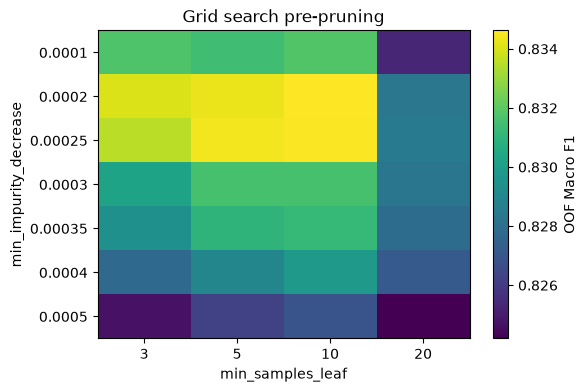

In [44]:
from joblib import Parallel, delayed

def grid_score(gain, leaf):
    params = dict(criterion=CFG.GRID_CRITERION, max_depth=30, min_samples_leaf=leaf, min_impurity_decrease=gain)
    return {'min_gain': gain, 'min_samples_leaf': leaf,
            'OOF Macro F1': best_threshold(y_clean, oof_proba(params, CFG.FEATURE_ENGINEERING, folds))[1]}

grid = pd.DataFrame(Parallel(n_jobs=-1)(delayed(grid_score)(g, l) for g in CFG.MIN_GAINS for l in CFG.LEAVES))
pivot = grid.pivot(index='min_gain', columns='min_samples_leaf', values='OOF Macro F1')

# rata-rata skor sel dan tetangganya
def pick_robust(pivot):
    v = pivot.to_numpy()
    smooth = np.full_like(v, np.nan)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            smooth[i, j] = np.nanmean(v[max(i - 1, 0):i + 2, max(j - 1, 0):j + 2])
    i, j = np.unravel_index(np.nanargmax(smooth), v.shape)
    return pivot.index[i], pivot.columns[j]

best_gain, best_leaf = pick_robust(pivot)
print('pilihan grid: min_gain', best_gain, ' min_samples_leaf', best_leaf, ' | DT_PARAMS:', CFG.DT_PARAMS)
plt.figure(figsize=(6, 4))
plt.imshow(pivot, cmap='viridis', aspect='auto')
plt.colorbar(label='OOF Macro F1')
plt.yticks(range(len(pivot.index)), [f'{g:g}' for g in pivot.index])
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.ylabel('min_impurity_decrease'); plt.xlabel('min_samples_leaf'); plt.title('Grid search pre-pruning')
plt.show()

#### Insights

- Grid memilih `min_impurity_decrease` 2e-4 dan `min_samples_leaf` 5, sama dengan eksperimen dt_gain_ratio.

In [45]:
oof = oof_proba(CFG.DT_PARAMS, CFG.FEATURE_ENGINEERING, folds)
rows = [report('versi ini', oof, folds)]
if CFG.PREV_PARAMS is not None:
    oof_prev = oof_proba(CFG.PREV_PARAMS, CFG.PREV_FEATURE_ENGINEERING, folds)
    rows.append(report('versi sebelumnya', oof_prev, folds))
scores = pd.DataFrame(rows).set_index('model')
DT_THRESHOLD = scores.loc['versi ini', 'threshold']
scores.round(4)

,threshold,OOF Macro F1,rata-rata fold,std fold
model,,,,
versi ini,0.51,0.8343,0.8343,0.0028
versi sebelumnya,0.43,0.8332,0.8332,0.0045


In [46]:
# cek di pembagian fold lain (seed 1 sampai 5) supaya kenaikan tidak hanya kebetulan di seed 42
seed_rows = []
for seed in [1, 2, 3, 4, 5]:
    seed_folds = stratified_kfold(y_clean, CFG.N_FOLDS, seed)
    row = {'seed': seed, 'versi ini': best_threshold(y_clean, oof_proba(CFG.DT_PARAMS, CFG.FEATURE_ENGINEERING, seed_folds))[1]}
    if CFG.PREV_PARAMS is not None:
        row['versi sebelumnya'] = best_threshold(y_clean, oof_proba(CFG.PREV_PARAMS, CFG.PREV_FEATURE_ENGINEERING, seed_folds))[1]
    seed_rows.append(row)
seeds = pd.DataFrame(seed_rows).set_index('seed')
if CFG.PREV_PARAMS is not None:
    seeds['selisih'] = seeds['versi ini'] - seeds['versi sebelumnya']
seeds.loc['rata-rata'] = seeds.mean()
seeds.round(4)

,versi ini,versi sebelumnya,selisih
seed,,,
1,0.8341,0.8316,0.0025
2,0.8370,0.8304,0.0066
3,0.8354,0.8322,0.0032
4,0.8347,0.8304,0.0042
5,0.8338,0.8329,0.0008
rata-rata,0.8350,0.8315,0.0035


#### Insights

- OOF seed 42 = 0.8343 dengan std per fold 0.0028, paling kecil dari semua versi, jadi paling stabil antarfold.
- Di seed 1 sampai 5, naik di 5 dari 5 seed dibanding `dtl_entropy_mingain` (rata-rata +0.0035). Dibanding `dtl_gini_mingain` (gini), rata-rata 0.8350 vs 0.8322.
- Public 0.84679, tertinggi untuk DTL.
- Pohon lebih dalam (depth 26, 253 leaf) karena gain ratio mau membuat split yang memisahkan kelompok kecil asalkan murni.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [47]:
# scikit-learn butuh input numerik tanpa NaN: kategori di-onehot dan missing diisi median data fit.
# Hasilnya tidak identik dengan from scratch karena missing dan kategori ditangani berbeda.
def to_numeric(fit, *others):
    frames = [pd.get_dummies(f, columns=cat_col, dtype=float) for f in (fit,) + others]
    frames = [f.reindex(columns=frames[0].columns, fill_value=0.0) for f in frames]
    median = frames[0].median()
    return [f.fillna(median) for f in frames]

X_train_num, X_val_num = to_numeric(X_train, X_val)
sk_params = dict(CFG.DT_PARAMS)
sk_params['criterion'] = 'entropy' if sk_params['criterion'] == 'gain_ratio' else sk_params['criterion']
models = {'from scratch': dt,
          'scikit-learn (parameter sama)': DecisionTreeClassifier(**sk_params, random_state=CFG.SEED),
          'sklearn ID3 (entropy)': DecisionTreeClassifier(criterion='entropy', random_state=CFG.SEED),
          'sklearn C4.5 (entropy + ccp_alpha)': DecisionTreeClassifier(criterion='entropy', ccp_alpha=3e-4, random_state=CFG.SEED),
          'sklearn CART (gini)': DecisionTreeClassifier(criterion='gini', random_state=CFG.SEED)}
rows = {}
for name, model in models.items():
    if name == 'from scratch':
        proba = model.predict_proba(X_val)
    else:
        proba = model.fit(X_train_num, y_train).predict_proba(X_val_num)[:, 1]
    rows[name] = {'jumlah leaf': model.get_n_leaves(), 'Macro F1 holdout (threshold terbaik)': best_threshold(y_val, proba)[1]}
pd.DataFrame(rows).T.round(4)

,jumlah leaf,Macro F1 holdout (threshold terbaik)
from scratch,253.0,0.8351
scikit-learn (parameter sama),444.0,0.8299
sklearn ID3 (entropy),2507.0,0.8167
sklearn C4.5 (entropy + ccp_alpha),337.0,0.8349
sklearn CART (gini),2637.0,0.8117


#### Insights

- sklearn tidak bisa membaca NaN dan teks, jadi untuk sklearn kategori di-onehot dan missing diisi median. Karena cara menangani missing dan kategori berbeda, hasilnya mirip tetapi tidak identik dengan from scratch.
- sklearn tidak punya gain ratio, jadi dibandingkan dengan entropy dan parameter lain yang sama: sklearn 444 leaf dengan holdout 0.8299, from scratch gain ratio 253 leaf dengan holdout 0.8351. Gain ratio membuat pohon lebih kecil dan lebih akurat.
- Varian yang diminta spesifikasi di sklearn: ID3 (entropy, tanpa batas) 0.8167, C4.5 (entropy + ccp_alpha) 0.8349, CART (gini, tanpa batas) 0.8117. Pohon tanpa batas (2.500 sampai 2.900 leaf) selalu paling rendah karena overfit.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [48]:
def save_model(model, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)

def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

In [49]:
# model final dilatih di seluruh data latih (setelah dedupe), preprocessing di-fit ulang di data yang sama
X_full, X_test_full = prepare_tree(train_clean, test_df, feature_engineering=CFG.FEATURE_ENGINEERING)
final_model = DecisionTree(**CFG.DT_PARAMS).fit(X_full, y_clean)
save_model({'model': final_model, 'threshold': DT_THRESHOLD}, CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)
print('model disimpan dan dimuat ulang dari', CFG.MODEL_PATH)
print('kedalaman', final_model.get_depth(), ' jumlah leaf', final_model.get_n_leaves(), ' threshold', DT_THRESHOLD)

model disimpan dan dimuat ulang dari output/models/dtl_gain_ratio.pkl
kedalaman 26  jumlah leaf 253  threshold 0.51


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [50]:
submission = pd.DataFrame({CFG.ID_COLUMN: test_df[CFG.ID_COLUMN],
                           CFG.TARGET: bundle['model'].predict(X_test_full, threshold=bundle['threshold'])})
Path(CFG.SUB_PATH).parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(CFG.SUB_PATH, index=False)
print('rasio batal prediksi', submission[CFG.TARGET].mean().round(4))
print('md5 submission:', hashlib.md5(open(CFG.SUB_PATH, 'rb').read()).hexdigest())
submission.head()

rasio batal prediksi 0.3093
md5 submission: 71abf10d033c2f0c8f5912b94ab2ba51


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

## Confusion Matrix

In [51]:
oof_pred = (oof >= DT_THRESHOLD).astype(int)
print('confusion matrix OOF [[TN, FP], [FN, TP]]')
print(confusion_matrix(y_clean, oof_pred))
print('F1 kelas 0, kelas 1:', f1_score(y_clean, oof_pred, average=None).round(4))

confusion matrix OOF [[TN, FP], [FN, TP]]
[[16613  1752]
 [ 2184  6760]]
F1 kelas 0, kelas 1: [0.8941 0.7745]


## Feature Importance

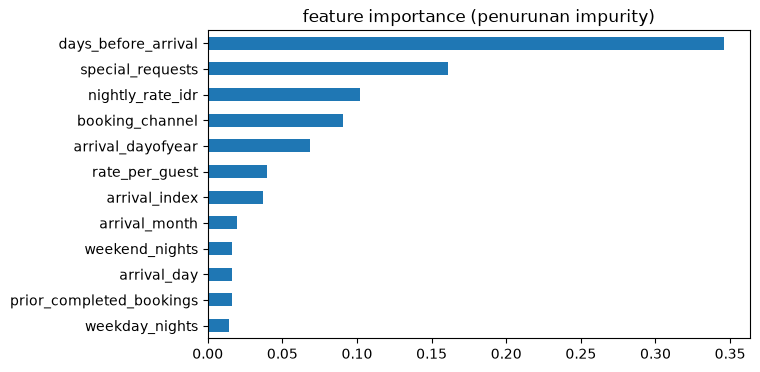

In [52]:
importance = pd.Series(final_model.feature_importances_, index=final_model.feature_names_).sort_values()
importance.tail(12).plot.barh(figsize=(7, 4), title='feature importance (penurunan impurity)')
plt.show()

## Gambar Percabangan

`plot_tree` menggambar `top_n` level teratas pohon. Leaf merah berarti mayoritas batal, hijau mayoritas tidak batal.

In [53]:
# Gambar percabangan pohon sampai kedalaman top_n.
def split_text(model, node):
    if node.is_cat:
        return model.describe_split(node)
    name, value = model.feature_names_[node.feature], node.threshold
    return f'{name} <= {value:,.0f}' if abs(value) >= 1000 else f'{name} <= {value:.4g}'

def plot_tree(model, top_n=3):
    figure, axis = plt.subplots(figsize=(2.8 * 2 ** top_n, 1.7 * (top_n + 1)))

    def draw(node, depth, x_min, x_max, parent=None):
        x, y = (x_min + x_max) / 2, -depth
        stop = node.is_leaf or depth == top_n
        text = (f'p(batal) = {node.value:.2f}\nn = {node.n_samples}' + ('' if node.is_leaf else '\n(lanjut)') if stop
                else f'{split_text(model, node)}\nn = {node.n_samples}')
        axis.text(x, y, text, ha='center', va='center', fontsize=8,
                  bbox=dict(boxstyle='round', fc='mistyrose' if stop and node.value >= 0.5 else 'honeydew' if stop else 'aliceblue'))
        if parent is not None:
            axis.plot([parent[0], x], [parent[1] - 0.22, y + 0.22], color='gray', lw=0.8)
        if not stop:
            mid = (x_min + x_max) / 2
            draw(node.left, depth + 1, x_min, mid, (x, y))
            draw(node.right, depth + 1, mid, x_max, (x, y))

    draw(model.root_, 0, 0, 1)
    axis.set_xlim(0, 1)
    axis.set_ylim(-top_n - 0.6, 0.6)
    axis.axis('off')
    axis.set_title(f'{top_n} level teratas Decision Tree (cabang kiri = kondisi benar)')
    plt.show()

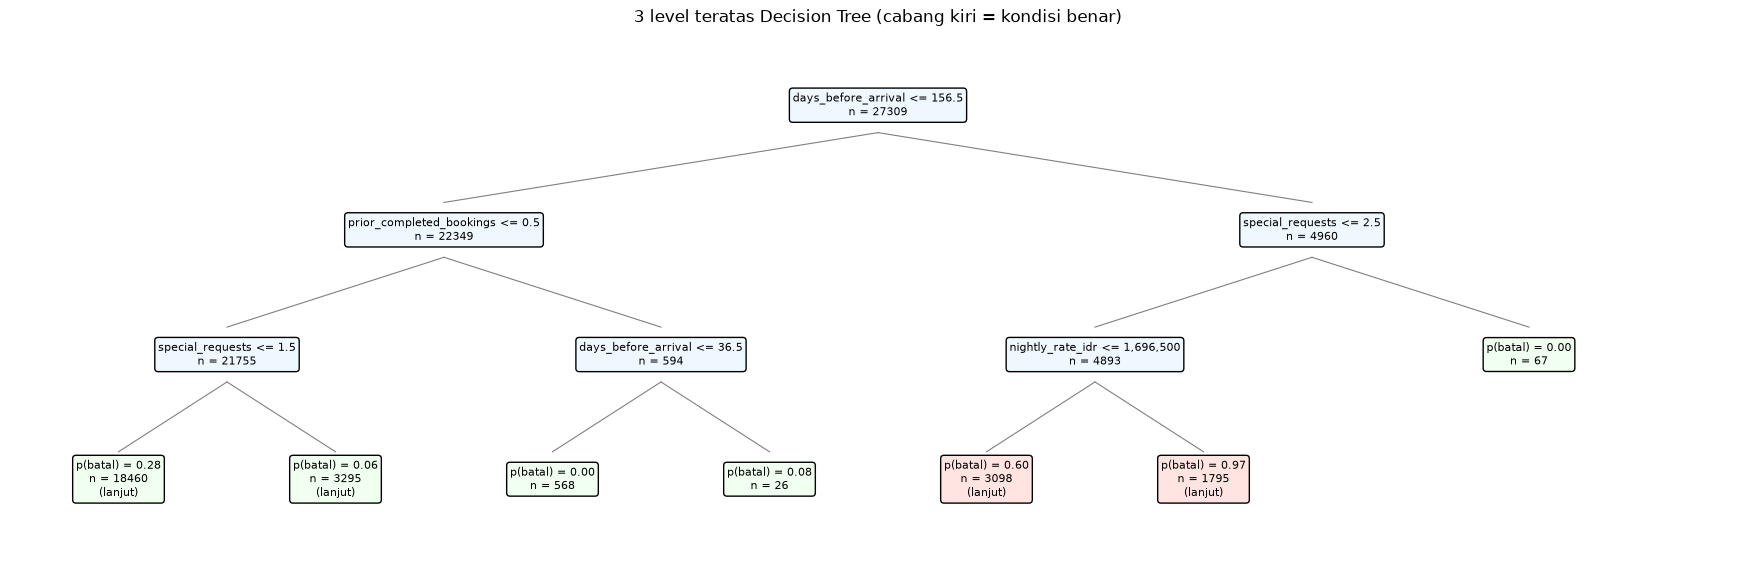

In [54]:
plot_tree(final_model, top_n=3)

## Kesalahan per Kelompok

In [55]:
def error_by(values, name):
    frame = pd.DataFrame({name: values, 'error': oof_pred != y_clean})
    return frame.groupby(name, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

display(error_by(pd.qcut(train_clean['days_before_arrival'], 5, duplicates='drop'), 'days_before_arrival'))
error_by(train_clean['special_requests'], 'special_requests')

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.096,5286
"(11.0, 39.0]",0.143,5332
"(39.0, 80.0]",0.162,5186
"(80.0, 151.0]",0.222,5180
"(151.0, 448.0]",0.079,5205
NaN,0.238,1120


,mean,size
special_requests,,
0.0,0.157,12678
1.0,0.149,8323
2.0,0.071,3246
3.0,0.010,496
4.0,0.017,60
5.0,0.000,7
NaN,0.188,2499


#### Insights

- Error tertinggi di lead time kosong (23,8%) dan lead time 80 sampai 151 hari (22,2%).
- Tamu dengan 3 atau lebih special_requests hampir tidak pernah salah diprediksi.